# Engine sanity check

Loads a logged simulation run (one heuristic bot vs. four random bots, rotating seats) and checks that the engine and logs behave sensibly before any RL training.

Generate the data with `uv run primary simulate --config configs/sim_heuristic.yaml`; the first cell creates it if it is missing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from primary.simulate import SimConfig, run_simulation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = SimConfig.from_yaml(ROOT / "configs" / "sim_heuristic.yaml")
RUN = ROOT / cfg.out_dir
if not (RUN / "games.parquet").exists():
    cfg.out_dir = str(RUN)
    run_simulation(cfg)
games = pd.read_parquet(RUN / "games.parquet")
rounds = pd.read_parquet(RUN / "rounds.parquet")
# only the columns used below, to keep memory low (the table has ~1M rows)
events = pd.read_parquet(RUN / "events.parquet", columns=["event_type", "detail", "amount"])
print(f"{len(games)} games, {len(rounds)} player-rounds, {len(events)} events")

1000 games, 55000 player-rounds, 1152341 events


## Win rates

A seat's win counts 1/k in a k-way draw. With 5 players, chance is 0.20.

In [2]:
rows = []
for g in games.itertuples():
    share = 1 / len(g.winners)
    for seat, (cand, pol, score) in enumerate(
        zip(g.candidates, g.policies, g.final_scores, strict=True)
    ):
        rows.append(
            {
                "game_id": g.game_id,
                "seat": seat,
                "candidate": cand,
                "policy": pol,
                "score": score,
                "win": share if seat in g.winners else 0.0,
            }
        )
seats = pd.DataFrame(rows)
seats.groupby("policy")["win"].agg(["mean", "count"]).rename(columns={"mean": "win rate"})

,win rate,count
policy,,
heuristic,0.97500,1000
random,0.00625,4000


The heuristic wins almost every game, so win rates of random-policy seats are all near zero. Mean final votes is a more informative (still rough) signal of candidate strength under random play; proper per-candidate estimates come from the trained policies in part 3.

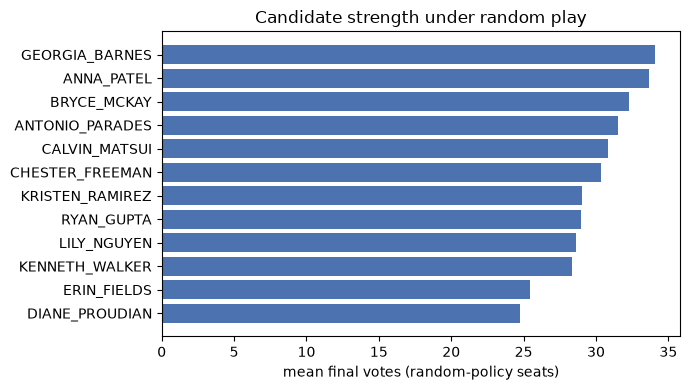

In [3]:
by_candidate = seats[seats.policy == "random"].groupby("candidate")["score"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_candidate.index, by_candidate.values, color="#4C72B0")
ax.set_xlabel("mean final votes (random-policy seats)")
ax.set_title("Candidate strength under random play")
fig.tight_layout()

## Final scores

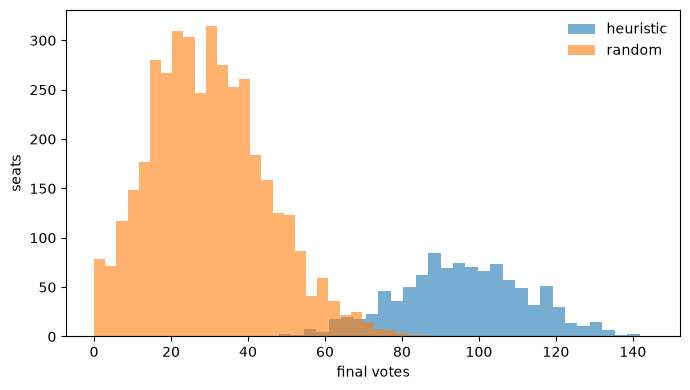

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for policy, group in seats.groupby("policy"):
    ax.hist(group.score, bins=30, alpha=0.6, label=policy)
ax.set_xlabel("final votes")
ax.set_ylabel("seats")
ax.legend(frameon=False)
fig.tight_layout()

## Round outcomes and cube flow

In [5]:
merged = rounds.merge(seats[["game_id", "seat", "policy"]], on=["game_id", "seat"])
pd.crosstab(merged.policy, merged.round_result, normalize="index").round(3)

round_result,lost,no_vote,not_participated,won
policy,,,,
heuristic,0.009,0.273,0.173,0.545
random,0.062,0.273,0.422,0.243


In [6]:
gains = events[events.event_type == "gain"].groupby("detail")["amount"].sum()
gains.sort_values(ascending=False).rename("cubes gained")

detail
fundraiser          52806.0
super_pac_tie       22956.0
super_pac           22824.0
tax_reform           5919.0
generous_donors      2965.0
colocation           2757.0
plutocracy_tie       1967.0
bryce                1871.0
plutocracy           1740.0
kenneth              1263.0
countermeasures      1014.0
deregulation          850.0
deregulation_tie      422.0
kristen               414.0
Name: cubes gained, dtype: float64

## Draws and tie-breakers

In [7]:
games.tiebreak.value_counts()

tiebreak
score    999
hand       1
Name: count, dtype: int64

**What to look for:** the heuristic should win far more than 20% of seats; every non-voting round (1, 4, 9) should be `no_vote`; draws should be rare.